# Phase II · 02 · Inside the fine-tuned ResNet18

Phase I showed that ResNet18 is more accurate than the CNN on clean images but loses more fakes under blur and resizing, and reacts strongly to noise. This notebook follows selected original/edited image pairs into the network:

| View | Lecture technique | What it shows |
| --- | --- | --- |
| Grad-CAM (4) | Gradient-based attribution | Positive support for FAKE on the native 7×7 grid of the last residual stage |
| Output contributions (4) | Exact linear decomposition | 512 pooled features × output weights + bias = REAL logit |
| Occlusion (4) | Perturbation-based attribution | Score change when a native 4×4 patch is covered |
| Stem filters, responses, top examples (5) | Weight and activation visualization | What the 64 first-layer filters look like and what activates them |
| Channel interventions (5) | Ablation | Whether removing one stem or final channel repairs the resize failure |
| Interactive comparison (6) | Explorable explanation | All views for any preview image, edit and channel (live kernel) |

The trained weights and saved analysis are downloaded (checksummed) from the team release the first time the notebook runs; nothing is fine-tuned. The cells are Sections 7–9 of `resnet18_finetuning.ipynb`, moved here with new section numbers.

## 1. Environment

The run was prepared with PyTorch 2.15.0 and torchvision 0.29.1 on an Apple GPU. CPU review is supported. The optional installer uses a compatible PyTorch range because wheel availability differs by operating system. Choose the notebook's Python environment before running it; all implementation code is contained here.

In [1]:
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    import sys, subprocess, importlib.util

    if importlib.util.find_spec("pip") is None:
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"])
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "torch>=2.14,<2.16",
            "torchvision==0.29.1",
            "numpy>=2.0",
            "pillow>=11",
            "scikit-learn>=1.5",
            "matplotlib>=3.9",
            "ipywidgets>=8",
            "nbformat>=5",
            "nbclient>=0.10",
            "ipykernel>=6",
        ]
    )


## 2. Configuration and preprocessing

Every native 32×32 RGB image is resized directly to 224×224, then normalized with the ImageNet mean and standard deviation. This intentionally preserves the full frame instead of using the pretrained weights' default resize-and-centre-crop recipe. Upsampling adds no new image detail. All robustness edits and occlusion masks are applied at native 32×32 **before** this fixed preprocessing.

This notebook only **reviews** the completed model. The hidden cells below are the same code as in `resnet18_finetuning.ipynb`, without the training, publishing and background-run functions.

In [2]:
# Review mode opens the completed model and its results. It does not start fine-tuning.
from pathlib import Path
from io import BytesIO, StringIO
from datetime import datetime, timezone
from contextlib import contextmanager
import os, sys, time, json, csv, hashlib, random, shutil, subprocess, signal, fcntl, copy, base64, zipfile, urllib.request, urllib.error
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import torchvision
from PIL import Image, ImageFilter, features as pillow_features
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
else:
    plt.switch_backend("Agg")

NOTEBOOK_PATH = Path.cwd().resolve() / "02_resnet18_internals.ipynb"
# Phase notebooks sit one folder below the repository root; data, runs and results stay at the root.
ROOT = next(
    (p for p in (NOTEBOOK_PATH.parent, *NOTEBOOK_PATH.parents) if (p / "team-info.json").exists()),
    NOTEBOOK_PATH.parent,
)
RUN_NAME = "resnet18_plain_seed1"
RUN_DIR = ROOT / "runs" / RUN_NAME
DATA_DIR = ROOT / "data" / "baseline_seed1"
SHARE_DIR = RUN_DIR / "share"
MODEL_SAVES = ROOT / "model_saves"
WEIGHTS_PATH = MODEL_SAVES / f"{RUN_NAME}.pt"
MODE = "review"  # Fixed: train in resnet18_finetuning.ipynb.
DOWNLOAD_SHARED_MODEL = (
    True  # Download the completed, checksummed model package in review mode.
)
START_BACKGROUND = (
    False  # Set True to run train/resume/finalize independently of the notebook kernel.
)
PUBLISH_TO_GITHUB = True  # The overnight pipeline uploads the finished model package to the team release.
REPOSITORY = "adamp-22/kandy"
RELEASE_TAG = "resnet18-plain-seed1-v1"
DEVICE = "auto"
MANIFEST_SHA256 = "098210d89f9441376008d520f72aeef5f65a7aa6b5e0073ba4e875c979e1f205"
TRAINING = dict(
    seed=1,
    epochs=25,
    warmup_epochs=2,
    batch_size=64,
    backbone_lr=1e-4,
    head_lr=1e-3,
    weight_decay=1e-4,
    patience=5,
    min_delta=1e-4,
    checkpoint_batches=200,
    max_hours=6.0,
)
torch.set_num_threads(4)


**Shared utilities.** These small helpers choose the device, save files safely and keep scores and model fingerprints consistent. The setup cells are collapsed by default; expand them to inspect the implementation.

In [3]:
def utc_now():
    return datetime.now(timezone.utc).isoformat()


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def atomic_json(path, value):
    """Write a complete temporary file before replacing the previous report."""
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    temp = p.with_name(p.name + ".tmp")
    temp.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temp.replace(p)


def atomic_torch(path, value):
    """Replace a checkpoint only after all of its bytes have been written."""
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    temp = p.with_name(p.name + ".tmp")
    with temp.open("wb") as f:
        torch.save(value, f)
        f.flush()
        os.fsync(f.fileno())
    temp.replace(p)


def device_for(name="auto"):
    if name == "auto":
        name = (
            "cuda"
            if torch.cuda.is_available()
            else "mps" if torch.backends.mps.is_available() else "cpu"
        )
    return torch.device(name)


def pfake(z):
    """Convert the REAL logit to a stable probability of FAKE."""
    return np.exp(-np.logaddexp(0, np.asarray(z, dtype=np.float64)))


def table(headers, rows):
    display(
        Markdown(
            "\n".join(
                [
                    "| " + " | ".join(headers) + " |",
                    "| " + " | ".join(["---"] * len(headers)) + " |",
                ]
                + ["| " + " | ".join(map(str, row)) + " |" for row in rows]
            )
        )
    )


def model_digest(net):
    """Fingerprint the actual tensors so results cannot be mixed between models."""
    h = hashlib.sha256()
    for key, value in sorted(net.state_dict().items()):
        h.update(key.encode())
        h.update(str(value.dtype).encode())
        h.update(str(tuple(value.shape)).encode())
        h.update(value.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()


**The model and its input.** This class starts with ImageNet ResNet18, replaces its classifier with one REAL logit, and keeps resizing and normalization inside the model. The additional forward methods expose feature maps for the later investigations.

In [4]:
class CifakeResNet18(nn.Module):
    """Native RGB [0,1] -> full-frame 224 resize -> ImageNet normalization -> one REAL logit."""

    def __init__(self, pretrained=False):
        super().__init__()
        if pretrained:
            torch.hub.set_dir(str(ROOT / "runs" / "_pretrained_cache"))
        self.net = torchvision.models.resnet18(
            weights=(
                torchvision.models.ResNet18_Weights.IMAGENET1K_V1
                if pretrained
                else None
            )
        )
        # Replace the ImageNet classifier with one output: a positive logit means REAL.
        self.net.fc = nn.Linear(self.net.fc.in_features, 1)
        self.register_buffer(
            "mean", torch.tensor([0.485, 0.456, 0.406])[None, :, None, None]
        )
        self.register_buffer(
            "std", torch.tensor([0.229, 0.224, 0.225])[None, :, None, None]
        )

    def preprocess(self, x):
        # Resize the whole image; this changes the input size but adds no new detail.
        return (
            F.interpolate(
                x, size=(224, 224), mode="bilinear", align_corners=False, antialias=True
            )
            - self.mean
        ) / self.std

    def forward(self, x):
        return self.net(self.preprocess(x)).squeeze(1)

    def forward_maps(self, x):
        b = self.net
        x = self.preprocess(x)
        stem = b.relu(b.bn1(b.conv1(x)))
        last = b.layer4(b.layer3(b.layer2(b.layer1(b.maxpool(stem)))))
        pooled = b.avgpool(last).flatten(1)
        return stem, last, pooled, b.fc(pooled).squeeze(1)

    def continue_stem(self, stem):
        b = self.net
        last = b.layer4(b.layer3(b.layer2(b.layer1(b.maxpool(stem)))))
        return b.fc(b.avgpool(last).flatten(1)).squeeze(1)


**Data checks and evaluation.** We verify the original split and image files, then calculate predictions and metrics at a fixed threshold. This avoids silently comparing models on different images.

In [5]:
def load_split(split, data_dir=DATA_DIR, expected=MANIFEST_SHA256):
    directory = Path(data_dir)
    audit = json.loads((directory / "audit.json").read_text())
    if sha256(directory / "manifest.csv") != expected:
        raise ValueError("The data split is different from the baseline split.")
    for filename in [f"{split}_images.npy", f"{split}_labels.npy"]:
        if sha256(directory / filename) != audit["file_sha256"][filename]:
            raise ValueError(f"Data integrity failure: {filename}")
    images = np.load(directory / f"{split}_images.npy", allow_pickle=False)
    labels = np.load(directory / f"{split}_labels.npy", allow_pickle=False)
    with (directory / "manifest.csv").open(newline="") as f:
        rows = [r for r in csv.DictReader(f) if r["split"] == split]
    assert images.shape == (len(labels), 3, 32, 32) and images.dtype == np.uint8
    assert np.array_equal(labels, [int(r["label"]) for r in rows])
    return images, labels, rows


def metrics(labels, z):
    """Report accuracy and both kinds of mistake at the fixed decision threshold."""
    labels = np.asarray(labels, dtype=int)
    z = np.asarray(z, dtype=np.float64)
    pred = (z >= 0).astype(int)
    assert np.isfinite(z).all() and len(z) == len(labels)
    cm = confusion_matrix(labels, pred, labels=[0, 1])
    return dict(
        n=len(labels),
        loss=float(np.mean(np.logaddexp(0, z) - labels * z)),
        accuracy=float(np.mean(pred == labels)),
        balanced_accuracy=float(np.mean(np.diag(cm) / cm.sum(1))),
        f1_fake=float(f1_score(labels, pred, pos_label=0)),
        roc_auc_fake=float(roc_auc_score(labels == 0, -z)),
        fake_detection_rate=float(cm[0, 0] / cm[0].sum()),
        real_flagged_fake_rate=float(cm[1, 0] / cm[1].sum()),
        brier_score_fake=float(np.mean((pfake(z) - (labels == 0)) ** 2)),
        confusion_matrix=cm.tolist(),
        confusion_matrix_order=["FAKE", "REAL"],
    )


@torch.inference_mode()
def predict(net, images, selected_device, batch_size=64):
    """Run evaluation batches without updating the weights or tracking gradients."""
    net.eval()
    result = []
    for start in range(0, len(images), batch_size):
        x = (
            torch.tensor(
                np.ascontiguousarray(images[start : start + batch_size]),
                device=selected_device,
                dtype=torch.float32,
            )
            / 255
        )
        result.append(net(x).cpu().numpy())
    return np.concatenate(result)


In [6]:
PROBE_SEED = 2026

PROBE_FAMILIES = {
    "JPEG": {
        "values": [95, 80, 60, 40],
        "axis": "JPEG quality",
        "labels": ["q95", "q80", "q60", "q40"],
    },
    "Blur": {
        "values": [0.3, 0.6, 1.0, 1.5],
        "axis": "Blur standard deviation (pixels)",
        "labels": ["0.3 px", "0.6 px", "1.0 px", "1.5 px"],
    },
    "Resize": {
        "values": [28, 24, 20, 16],
        "axis": "Intermediate image width (pixels)",
        "labels": ["28 px", "24 px", "20 px", "16 px"],
    },
    "Noise": {
        "values": [0.01, 0.03, 0.05, 0.10],
        "axis": "Noise standard deviation (RGB in [0, 1])",
        "labels": ["0.01", "0.03", "0.05", "0.10"],
    },
}


def behavior_conditions():
    """Use the same named modification strengths for every image and model."""
    conditions = [
        {"family": "Original", "value": None, "label": "Original", "level": 0}
    ]
    for family, spec in PROBE_FAMILIES.items():
        for level, (value, label) in enumerate(
            zip(spec["values"], spec["labels"]), start=1
        ):
            conditions.append(
                {"family": family, "value": value, "label": label, "level": level}
            )
    return conditions


def modify_behavior_image(image, family, value, image_index, seed=PROBE_SEED):
    """Pure pixel transformation: uint8 CHW in/out, always 3x32x32."""
    assert image.dtype == np.uint8 and image.shape == (3, 32, 32)
    if family == "Original":
        return image.copy()
    if family == "Noise":
        # Reuse one noise field per image at every strength and in the explorer.
        rng = np.random.default_rng(np.random.SeedSequence([seed, int(image_index)]))
        noise = rng.standard_normal(image.shape, dtype=np.float32)
        changed = np.clip(image.astype(np.float32) / 255 + float(value) * noise, 0, 1)
        return np.rint(changed * 255).astype(np.uint8)
    source = Image.fromarray(image.transpose(1, 2, 0))
    if family == "JPEG":
        stream = BytesIO()
        # Keep chroma sampling fixed at 4:4:4; vary quality only.
        source.save(
            stream,
            format="JPEG",
            quality=int(value),
            subsampling=0,
            optimize=False,
            progressive=False,
        )
        stream.seek(0)
        with Image.open(stream) as decoded:
            result = np.array(decoded.convert("RGB"), dtype=np.uint8)
    elif family == "Blur":
        result = np.array(
            source.filter(ImageFilter.GaussianBlur(radius=float(value))), dtype=np.uint8
        )
    elif family == "Resize":
        width = int(value)
        result = np.array(
            source.resize((width, width), resample=Image.Resampling.BILINEAR).resize(
                (32, 32), resample=Image.Resampling.BILINEAR
            ),
            dtype=np.uint8,
        )
    else:
        raise ValueError(f"Unknown modification: {family}")
    return result.transpose(2, 0, 1).copy()


**Saved CNN comparison data.** The next cell loads the baseline CNN's saved validation predictions, labels and a small image preview set. The compressed data is embedded in this `.ipynb` file's metadata, so it does not fill the reading view with encoded text and no additional data file is needed. Its checksum is verified before use. The loading cell is marked as hidden for viewers that support this setting; it still runs normally.

In [7]:
# Saved validation predictions and a small preview set; no training runs here.
BEHAVIOR_METADATA_JSON = json.dumps(
    {
        "split": "val",
        "n": 10000,
        "class_counts": {"FAKE": 5000, "REAL": 5000},
        "model_state_sha256": "2b73e9f88f029ae7f9d33935864ceeefbd443b7d80a87e532301909a3c0a90a8",
        "selected_epoch": 19,
        "manifest_sha256": "098210d89f9441376008d520f72aeef5f65a7aa6b5e0073ba4e875c979e1f205",
        "seed": 2026,
        "conditions": [
            {"family": "Original", "value": None, "label": "Original", "level": 0},
            {"family": "JPEG", "value": 95, "label": "q95", "level": 1},
            {"family": "JPEG", "value": 80, "label": "q80", "level": 2},
            {"family": "JPEG", "value": 60, "label": "q60", "level": 3},
            {"family": "JPEG", "value": 40, "label": "q40", "level": 4},
            {"family": "Blur", "value": 0.3, "label": "0.3 px", "level": 1},
            {"family": "Blur", "value": 0.6, "label": "0.6 px", "level": 2},
            {"family": "Blur", "value": 1.0, "label": "1.0 px", "level": 3},
            {"family": "Blur", "value": 1.5, "label": "1.5 px", "level": 4},
            {"family": "Resize", "value": 28, "label": "28 px", "level": 1},
            {"family": "Resize", "value": 24, "label": "24 px", "level": 2},
            {"family": "Resize", "value": 20, "label": "20 px", "level": 3},
            {"family": "Resize", "value": 16, "label": "16 px", "level": 4},
            {"family": "Noise", "value": 0.01, "label": "0.01", "level": 1},
            {"family": "Noise", "value": 0.03, "label": "0.03", "level": 2},
            {"family": "Noise", "value": 0.05, "label": "0.05", "level": 3},
            {"family": "Noise", "value": 0.1, "label": "0.10", "level": 4},
        ],
        "gallery_indices": {
            "JPEG": {"FAKE": 752, "REAL": 9255},
            "Blur": {"FAKE": 3571, "REAL": 7473},
            "Resize": {"FAKE": 1358, "REAL": 7473},
            "Noise": {"FAKE": 50, "REAL": 6193},
        },
        "gallery_selection": "For each class and family, choose the largest shift "
        "toward the wrong class at level 2 among clean-correct "
        "validation images.",
        "preview_selection": "Gallery cases, largest score recoveries among "
        "clean-wrong images at level 2, and six seeded random "
        "examples per class; duplicates removed.",
        "decision_rule": "FAKE if P(FAKE)>0.5; otherwise REAL.",
        "transforms": {
            "JPEG": "Re-encode decoded RGB in memory, quality 95/80/60/40; "
            "fixed 4:4:4 chroma sampling, no "
            "optimization/progressive mode. Original control is "
            "not re-encoded.",
            "Blur": "Pillow GaussianBlur, standard deviation "
            "0.3/0.6/1.0/1.5 pixels.",
            "Resize": "32 -> 28/24/20/16 -> 32 with Pillow bilinear "
            "interpolation in both directions.",
            "Noise": "Independent Gaussian RGB noise in [0,1], sigma "
            "0.01/0.03/0.05/0.10; clipped to [0,1], rounded to "
            "uint8. Same seeded noise field per image across "
            "strengths.",
        },
        "environment": {
            "torch": "2.15.0",
            "numpy": "2.5.4",
            "pillow": "13.0.0",
            "jpeg_codec": "6.2",
            "device": "mps",
        },
        "elapsed_seconds": 10.356811792124063,
        "scope": "Exploratory validation-set model behavior. Fixed selected model; no "
        "training, no test evaluation, no causal claim about learned "
        "features.",
    }
)
BEHAVIOR_BUNDLE_SHA256 = (
    "c57176388e6d839f96c1fa443fd1b09079e9c2b72085b1ee8bd978fa1e8046bd"
)
# The encoded data lives in this notebook's metadata to keep the reading view compact.


def load_behavior_bundle():
    # Background runners receive the bundle from their frozen notebook snapshot.
    """Decode and check the saved validation predictions used by the figures."""
    encoded = globals().get("BEHAVIOR_BUNDLE")
    if encoded is None:
        if not NOTEBOOK_PATH.is_file():
            raise FileNotFoundError(
                f"Open/run this notebook from its project folder: {NOTEBOOK_PATH}"
            )
        saved_notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
        encoded = saved_notebook["metadata"]["cifake"]["baseline_validation_bundle"]
    raw = base64.b64decode(encoded, validate=True)
    assert hashlib.sha256(raw).hexdigest() == BEHAVIOR_BUNDLE_SHA256
    with np.load(BytesIO(raw), allow_pickle=False) as archive:
        arrays = {key: archive[key].copy() for key in archive.files}
    report = json.loads(BEHAVIOR_METADATA_JSON)
    assert arrays["p_fake"].shape == (len(report["conditions"]), report["n"])
    assert len(arrays["labels"]) == len(arrays["paths"]) == report["n"]
    assert np.isfinite(arrays["p_fake"]).all()
    assert ((arrays["p_fake"] >= 0) & (arrays["p_fake"] <= 1)).all()
    assert arrays["preview_images"].shape == (len(arrays["preview_indices"]), 3, 32, 32)
    assert arrays["preview_images"].dtype == np.uint8
    assert len(np.unique(arrays["preview_indices"])) == len(arrays["preview_indices"])
    assert report["conditions"] == behavior_conditions()
    return arrays, report


BASE_ARRAYS, BASE_REPORT = load_behavior_bundle()


**Loading the shared experiment.** This loader checks the downloaded files and restores the selected model with its saved predictions. It lets teammates review the completed experiment without training or downloading the full dataset.

In [8]:
def load_review_assets(
    download=DOWNLOAD_SHARED_MODEL, share_dir=SHARE_DIR, selected_device=None
):
    """Verify and load the published weights and analysis without fine-tuning."""
    share = Path(share_dir)
    manifest_path = share / "resnet18_manifest.json"
    if not manifest_path.exists() and download:
        base = f"https://github.com/{REPOSITORY}/releases/download/{RELEASE_TAG}/"
        try:
            with urllib.request.urlopen(
                base + "resnet18_manifest.json", timeout=20
            ) as response:
                raw = response.read()
        except urllib.error.HTTPError as error:
            if error.code == 404:
                print(
                    "The finished ResNet18 package has not been published yet. Review mode does not train a model."
                )
                return None, None, None
            raise
        share.mkdir(parents=True, exist_ok=True)
        manifest = json.loads(raw)
        for name, expected in manifest["assets"].items():
            if Path(name).name != name:
                raise ValueError("Invalid asset filename")
            target = share / name
            temporary = target.with_suffix(target.suffix + ".download")
            urllib.request.urlretrieve(base + name, temporary)
            if sha256(temporary) != expected:
                raise ValueError("Downloaded asset failed its checksum.")
            temporary.replace(target)
        manifest_path.write_bytes(raw)
    if not manifest_path.exists():
        print("No finished model package is available locally yet.")
        return None, None, None
    manifest = json.loads(manifest_path.read_text())
    for name, expected in manifest["assets"].items():
        if sha256(share / name) != expected:
            raise ValueError(f"Asset checksum mismatch: {name}")
    state_dict = torch.load(
        share / "resnet18_plain_seed1.pt", map_location="cpu", weights_only=True
    )
    device = (
        device_for(DEVICE) if selected_device is None else torch.device(selected_device)
    )
    net = CifakeResNet18(pretrained=False).to(device)
    net.load_state_dict(state_dict)
    net.eval()
    if model_digest(net) != manifest["model_digest"]:
        raise ValueError("Loaded weights do not match the published model.")
    arrays = dict(np.load(share / "resnet18_analysis.npz", allow_pickle=False))
    report = json.loads((share / "resnet18_report.json").read_text())
    assert (
        report["model_digest"] == manifest["model_digest"]
        and report["manifest_sha256"] == MANIFEST_SHA256
    )
    return net, arrays, report


**Preparing image pairs.** These helpers select the same image before and after a modification, then collect the tensors needed by the plots. No weights are updated.

In [9]:
resnet_pair_cache = {}
resnet_occlusion_cache = {}


def finish_plot(fig, name):
    if globals().get("SAVE_FIGURES", False):
        destination = RUN_DIR / "figures"
        destination.mkdir(parents=True, exist_ok=True)
        fig.savefig(destination / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def picture(ax, image, title):
    ax.imshow(image.transpose(1, 2, 0), interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.set(xticks=[], yticks=[])


def resnet_pair(index, family, level):
    """Gather explanations for the same image before and after one controlled modification."""
    key = (resnet_report["model_digest"], int(index), family, int(level))
    if key in resnet_pair_cache:
        return resnet_pair_cache[key]
    conditions = resnet_report["conditions"]
    indices = [0] + [i for i, c in enumerate(conditions) if c["family"] == family]
    condition = conditions[indices[int(level)]]
    original = resnet_previews[int(index)]
    changed = modify_behavior_image(
        original, condition["family"], condition["value"], int(index)
    )
    images = np.stack([original, changed])
    resnet_model.eval()
    with torch.inference_mode(False), torch.enable_grad():
        x = torch.tensor(images, device=device, dtype=torch.float32) / 255
        stem, last, pooled, z = resnet_model.forward_maps(x)
        gradient = torch.autograd.grad((-z).sum(), last)[0]
        cam = torch.relu((gradient.mean((2, 3), keepdim=True) * last).sum(1))
        contributions = pooled * resnet_model.net.fc.weight[0]
        bias = float(resnet_model.net.fc.bias[0].detach().cpu())
        values = dict(
            stem=stem.detach().cpu().numpy(),
            last=last.detach().cpu().numpy(),
            cam=cam.detach().cpu().numpy(),
            contributions=contributions.detach().cpu().numpy(),
            pooled=pooled.detach().cpu().numpy(),
            logits=z.detach().cpu().numpy(),
            bias=bias,
        )
    np.testing.assert_allclose(
        values["contributions"].sum(1) + bias, values["logits"], atol=5e-5, rtol=1e-5
    )
    pair = dict(
        index=int(index),
        images=images,
        values=values,
        family=family,
        level=int(level),
        setting="Original" if level == 0 else f'{family} {condition["label"]}',
        truth="FAKE" if resnet_data["val_labels"][index] == 0 else "REAL",
        path=str(resnet_data["val_paths"][index]),
    )
    if len(resnet_pair_cache) >= 16:
        resnet_pair_cache.pop(next(iter(resnet_pair_cache)))
    resnet_pair_cache[key] = pair
    return pair


**Training and performance figures.** The learning curves use recorded epoch history; the performance figures use the saved predictions. Their job is to make model selection and changes in errors visible.

In [10]:
def learning_figure():
    """Plot recorded epoch metrics and mark the checkpoint selected by validation loss."""
    h = resnet_report["history"]
    epochs = [r["epoch"] for r in h]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
    for ax, key, title in zip(
        axes, ["loss", "accuracy"], ["Binary cross entropy", "Accuracy"]
    ):
        ax.plot(epochs, [r["train_" + key] for r in h], label="Train")
        ax.plot(epochs, [r["val_" + key] for r in h], label="Validation")
        ax.axvline(
            resnet_report["selected_epoch"],
            color="black",
            ls="--",
            lw=1,
            label="Selected epoch",
        )
        ax.axvspan(
            0.5,
            resnet_report["training"]["warmup_epochs"] + 0.5,
            color="#dddddd",
            alpha=0.4,
        )
        ax.set(xlabel="Epoch", ylabel=title)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    return fig


def robustness_figure():
    """Compare both models on the same images, labels and modification strengths."""
    fig, axes = plt.subplots(3, 4, figsize=(14, 9), layout="constrained")
    base_z = -np.log(
        np.clip(BASE_ARRAYS["p_fake"], 1e-7, 1 - 1e-7)
        / (1 - np.clip(BASE_ARRAYS["p_fake"], 1e-7, 1 - 1e-7))
    )
    base_metrics = [metrics(BASE_ARRAYS["labels"], z) for z in base_z]
    for col, family in enumerate(PROBE_FAMILIES):
        indices = [0] + [
            i
            for i, c in enumerate(resnet_report["conditions"])
            if c["family"] == family
        ]
        for row, (key, label) in enumerate(
            [
                ("accuracy", "Accuracy"),
                ("fake_detection_rate", "Fake images detected"),
                ("real_flagged_fake_rate", "Real false alarms"),
            ]
        ):
            ax = axes[row, col]
            ax.plot(
                range(5),
                [resnet_report["condition_metrics"][i][key] for i in indices],
                marker="o",
                label="ResNet18",
            )
            ax.plot(
                range(5),
                [base_metrics[i][key] for i in indices],
                marker="s",
                ls="--",
                label="Plain CNN",
            )
            ax.set(
                xticks=range(5),
                xticklabels=["Original"] + PROBE_FAMILIES[family]["labels"],
                ylim=(-0.03, 1.03),
                ylabel=label,
            )
            if row == 0:
                ax.set_title(family)
            ax.tick_params(axis="x", labelrotation=25, labelsize=8)
            ax.grid(alpha=0.2)
    axes[0, 0].legend()
    fig.suptitle(
        "Same 10,000 validation images and native 32×32 edits · frozen selected models"
    )
    return fig


def confusion_figure():
    cm = np.asarray(resnet_report["evaluation"]["official_test"]["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
    ax.imshow(cm, cmap="Blues")
    for y in range(2):
        for x in range(2):
            ax.text(
                x,
                y,
                f"{cm[y,x]:,}",
                ha="center",
                va="center",
                color="white" if cm[y, x] > cm.max() / 2 else "black",
            )
    ax.set(
        xticks=[0, 1],
        xticklabels=["FAKE", "REAL"],
        yticks=[0, 1],
        yticklabels=["FAKE", "REAL"],
        xlabel="Predicted",
        ylabel="True",
        title="Official test · selected ResNet18",
    )
    return fig


**Regional and output explanations.** These functions draw Grad-CAM and contribution comparisons, and run small occlusion checks on the preview images. The comments distinguish coarse spatial evidence from an exact accounting of the final logit.

In [11]:
def gradcam_figure(pair):
    """Compare coarse positive support for FAKE using a shared visual scale."""
    fig, axes = plt.subplots(2, 3, figsize=(11, 7), layout="constrained")
    cam = pair["values"]["cam"]
    vmax = max(float(cam.max()), 1e-9)
    for side in range(2):
        name = "Original" if side == 0 else pair["setting"]
        p = pfake(pair["values"]["logits"][side])
        picture(axes[side, 0], pair["images"][side], f"{name} · P(FAKE) {p:.2%}")
        heat = axes[side, 1].imshow(
            cam[side], cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
        axes[side, 1].set(title="Native FAKE Grad-CAM · 7×7", xticks=[], yticks=[])
        picture(axes[side, 2], pair["images"][side], "Overlay on native input")
        resized = F.interpolate(
            torch.tensor(cam[side])[None, None],
            size=(32, 32),
            mode="bilinear",
            align_corners=False,
        )[0, 0].numpy()
        axes[side, 2].imshow(
            np.ma.masked_where(resized <= 0, resized),
            cmap="magma",
            vmin=0,
            vmax=vmax,
            alpha=0.55,
        )
    fig.colorbar(
        heat,
        ax=list(axes[:, 1:].flat),
        shrink=0.7,
        label="Positive FAKE Grad-CAM · shared scale",
    )
    fig.suptitle(
        f"Target fixed at FAKE (−REAL logit) · true label {pair['truth']}\n{pair['path']}"
    )
    return fig


def contribution_figure(pair):
    """Show how feature values times output weights add up to the model score."""
    c = pair["values"]["contributions"].astype(np.float64)
    delta = c[1] - c[0]
    order = np.argsort(-np.abs(delta), kind="stable")[:12]
    other = np.ones(512, bool)
    other[order] = False
    bars = np.r_[delta[order], delta[other].sum()]
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(12, 7),
        layout="constrained",
        gridspec_kw={"height_ratios": [1, 3]},
    )
    vmax = max(float(np.abs(c).max()), 1e-9)
    heat = axes[0].imshow(c, aspect="auto", cmap="RdBu", vmin=-vmax, vmax=vmax)
    axes[0].set(
        yticks=[0, 1],
        yticklabels=["Original", pair["setting"]],
        xlabel="Final feature channel (0–511)",
        title="All 512 pooled-activation × output-weight contributions",
    )
    fig.colorbar(heat, ax=axes[0], shrink=0.8, label="Contribution to REAL logit")
    axes[1].barh(
        range(13), bars, color=["#0072B2" if x >= 0 else "#D55E00" for x in bars]
    )
    axes[1].set(
        yticks=range(13),
        yticklabels=[f"Channel {i}" for i in order] + ["Other 500 channels"],
        xlabel="Change in REAL logit contribution",
    )
    axes[1].invert_yaxis()
    axes[1].axvline(0, color="black", lw=0.8)
    z = pair["values"]["logits"]
    fig.suptitle(
        f'Exact final-layer accounting · REAL logit {z[0]:+.3f} → {z[1]:+.3f} · fixed bias {pair["values"]["bias"]:+.4f}'
    )
    return fig


@torch.inference_mode()
def native_occlusion(image, reference, patch=4):
    """Cover patches on the original 32 by 32 image, then pass them through ResNet preprocessing."""
    stride = patch // 2
    starts = list(range(0, 33 - patch, stride))
    positions = [(y, x) for y in starts for x in starts]
    x = torch.tensor(image, device=device, dtype=torch.float32)[None] / 255
    original = float(resnet_model(x).cpu()[0])
    drops = []
    fill = torch.tensor(reference, device=device, dtype=torch.float32)
    for start in range(0, len(positions), 64):
        current = positions[start : start + 64]
        batch = x.expand(len(current), -1, -1, -1).clone()
        for i, (y, xpos) in enumerate(current):
            batch[i, :, y : y + patch, xpos : xpos + patch] = fill[:, None, None]
        drops.extend((resnet_model(batch) - original).cpu().numpy().tolist())
    sums = np.zeros((32, 32))
    coverage = np.zeros((32, 32))
    for (y, xpos), drop in zip(positions, drops):
        sums[y : y + patch, xpos : xpos + patch] += drop
        coverage[y : y + patch, xpos : xpos + patch] += 1
    assert np.all(coverage > 0)
    return sums / coverage


def occlusion_figure(pair, patch=4):
    reference_names = ["Original mean RGB", "Mid-grey RGB"]
    references = [pair["images"][0].mean((1, 2)) / 255, np.full(3, 0.5)]
    maps = []
    for side in range(2):
        row = []
        for reference in references:
            key = (
                resnet_report["model_digest"],
                pair["index"],
                pair["family"],
                pair["level"],
                side,
                reference.tobytes(),
                patch,
            )
            if key not in resnet_occlusion_cache:
                resnet_occlusion_cache[key] = native_occlusion(
                    pair["images"][side], reference, patch
                )
            row.append(resnet_occlusion_cache[key])
        maps.append(row)
    vmax = max(float(np.abs(maps).max()), 1e-9)
    fig, axes = plt.subplots(2, 3, figsize=(11, 7), layout="constrained")
    for side in range(2):
        picture(
            axes[side, 0],
            pair["images"][side],
            ("Original" if side == 0 else pair["setting"])
            + f" · P(FAKE) {pfake(pair['values']['logits'][side]):.2%}",
        )
        for j in range(2):
            heat = axes[side, j + 1].imshow(
                maps[side][j],
                cmap="RdBu_r",
                vmin=-vmax,
                vmax=vmax,
                interpolation="nearest",
            )
            axes[side, j + 1].set(title=reference_names[j], xticks=[], yticks=[])
    fig.colorbar(
        heat,
        ax=list(axes[:, 1:].flat),
        shrink=0.7,
        label="FAKE score before − after covering · red positive, blue negative",
    )
    fig.suptitle(
        f"Occlusion at native 32×32 · {patch}×{patch} patch · stride {patch//2}\nSame reference within each pair; one colour scale across all maps"
    )
    return fig


**Internal feature figures.** We display learned filters, response maps, activating examples and the saved channel-removal results. Shared scales help compare original and modified images.

In [12]:
def channel_figure(pair, stage, channel):
    maps = pair["values"][stage][:, channel]
    vmax = max(float(maps.max()), 1e-9)
    fig, axes = plt.subplots(2, 2, figsize=(8, 7), layout="constrained")
    with torch.inference_mode():
        if stage == "last":
            removed = (
                pair["values"]["logits"] - pair["values"]["contributions"][:, channel]
            )
        else:
            stem = torch.tensor(pair["values"]["stem"], device=device)
            stem[:, channel] = 0
            removed = resnet_model.continue_stem(stem).cpu().numpy()
    for side in range(2):
        picture(
            axes[side, 0],
            pair["images"][side],
            ("Original" if side == 0 else pair["setting"])
            + f"\nP(FAKE) {pfake(pair['values']['logits'][side]):.2%}; channel zeroed {pfake(removed[side]):.2%}",
        )
        heat = axes[side, 1].imshow(
            maps[side], cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
        axes[side, 1].set(
            title=f"{stage} channel {channel} · {maps.shape[-1]}×{maps.shape[-1]}",
            xticks=[],
            yticks=[],
        )
    fig.colorbar(
        heat,
        ax=list(axes[:, 1]),
        shrink=0.8,
        label="Post-ReLU activation · common scale",
    )
    fig.suptitle(
        "Stem = Conv–BatchNorm–ReLU; last = layer4 output after residual additions"
    )
    return fig


def weight_figure(stage="stem", channel=0):
    if stage == "last":
        weights = resnet_model.net.fc.weight[0].detach().cpu().numpy()
        fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
        ax.bar(range(512), weights, color="#0072B2")
        ax.scatter([channel], [weights[channel]], color="#D55E00", zorder=5)
        ax.set(
            xlabel="Final feature channel",
            ylabel="Weight into REAL logit",
            title=f"Final linear weights · selected channel {channel} = {weights[channel]:+.4f}",
        )
        return fig
    weights = resnet_model.net.conv1.weight.detach().cpu().numpy()
    vmax = float(np.abs(weights).max())
    fig, axes = plt.subplots(8, 8, figsize=(14, 10), layout="constrained")
    for i, ax in enumerate(axes.flat):
        heat = ax.imshow(
            np.concatenate(list(weights[i]), axis=1),
            cmap="RdBu_r",
            vmin=-vmax,
            vmax=vmax,
            interpolation="nearest",
        )
        ax.set(title=str(i), xticks=[3, 10, 17], xticklabels=["R", "G", "B"], yticks=[])
        ax.tick_params(labelsize=7)
        if i == channel:
            for spine in ax.spines.values():
                spine.set_color("green")
                spine.set_linewidth(2)
    fig.colorbar(
        heat,
        ax=list(axes.flat),
        shrink=0.8,
        label="Learned convolution weight · shared scale",
    )
    fig.suptitle(
        "ResNet18 stem: 64 filters, each with three 7×7 RGB slices · BatchNorm and ReLU follow this convolution"
    )
    return fig


def examples_figure(stage, channel):
    slots = resnet_data[stage + "_top_slots"][channel]
    ids = resnet_data["cohort_indices"][slots]
    images = np.stack([resnet_examples[int(i)] for i in ids])
    with torch.inference_mode():
        stem, last, _, z = resnet_model.forward_maps(
            torch.tensor(images, device=device, dtype=torch.float32) / 255
        )
        maps = (stem if stage == "stem" else last)[:, channel].cpu().numpy()
    fig, axes = plt.subplots(3, 2, figsize=(7, 9), layout="constrained")
    vmax = max(float(maps.max()), 1e-9)
    for i, index in enumerate(ids):
        truth = "FAKE" if resnet_data["val_labels"][index] == 0 else "REAL"
        picture(
            axes[i, 0],
            images[i],
            f'{truth} · {Path(str(resnet_data["val_paths"][index])).name}',
        )
        heat = axes[i, 1].imshow(
            maps[i], cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
        axes[i, 1].set(
            title=f"Peak activation {maps[i].max():.3f}", xticks=[], yticks=[]
        )
    fig.colorbar(heat, ax=list(axes[:, 1]), shrink=0.7, label="Activation")
    fig.suptitle(
        f"{stage} channel {channel}: three strongest spatial responses in the fixed validation sample\nThese examples suggest response patterns, not semantic class labels."
    )
    return fig


def internal_figure():
    """Summarize the accuracy changes caused by removing individual channels."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 7), layout="constrained")
    for ax, stage in zip(axes, ["stem", "last"]):
        values = resnet_data[stage + "_ablation"][:, :, 0] * 100
        chosen = np.argsort(-np.abs(values[0]), kind="stable")[:20]
        for ci, name in enumerate(resnet_report["internal_conditions"]):
            ax.plot(values[ci, chosen], range(20), marker="o", label=name)
        ax.set(
            yticks=range(20),
            yticklabels=[str(i) for i in chosen],
            xlabel="Accuracy lost when channel is zeroed (pp)",
            ylabel="Channel",
            title=f"{stage}: 20 largest clean effects",
        )
        ax.invert_yaxis()
        ax.axvline(0, color="black", lw=0.8)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    fig.suptitle(
        f"Paired channel removal on the same {len(resnet_data['cohort_indices']):,} validation images\nPositive = removal hurts accuracy; negative = removal improves accuracy. All channels are available in the explorer."
    )
    return fig


**Interactive controls.** The explorer combines the same calculations into a selectable image, modification and channel view. It only works with the fixed trained model.

In [13]:
def draw_explorer():
    import ipywidgets as widgets
    import html

    image_choice = widgets.Dropdown(
        options=[
            (
                f"{'FAKE' if resnet_data['val_labels'][int(i)]==0 else 'REAL'} · {resnet_data['val_paths'][int(i)]}",
                int(i),
            )
            for i in resnet_data["preview_indices"]
        ],
        value=default_pair["index"],
        description="Image:",
        layout=widgets.Layout(width="95%"),
    )
    family_choice = widgets.Dropdown(
        options=list(PROBE_FAMILIES), value="Resize", description="Change:"
    )
    level_choice = widgets.IntSlider(
        value=1, min=0, max=4, description="Strength:", continuous_update=False
    )
    stage_choice = widgets.Dropdown(
        options=[("Stem", "stem"), ("Final features", "last")],
        value="stem",
        description="Stage:",
    )
    channel_choice = widgets.IntSlider(
        value=default_stem_channel,
        min=0,
        max=63,
        description="Channel:",
        continuous_update=False,
    )
    patch_choice = widgets.Dropdown(options=[4, 8], value=4, description="Patch:")
    button = widgets.Button(description="Inspect", button_style="primary")
    status = widgets.HTML()
    details = widgets.HTML()
    pictures = [
        widgets.Image(format="png", layout=widgets.Layout(width="100%"))
        for _ in range(7)
    ]
    stats = widgets.HTML()
    tabs = widgets.Tab(
        children=[
            widgets.VBox(pictures[:2]),
            pictures[2],
            pictures[3],
            pictures[4],
            pictures[5],
            pictures[6],
            stats,
        ]
    )
    for i, title in enumerate(
        [
            "Attribution",
            "Occlusion",
            "Channel",
            "Weights",
            "Examples",
            "All effects",
            "Selected effects",
        ]
    ):
        tabs.set_title(i, title)
    state = {}

    def stale(change=None):
        status.value = "Settings changed; press Inspect. The current plots still show the last completed selection."

    def stage_changed(change):
        channel_choice.max = 63 if stage_choice.value == "stem" else 511
        channel_choice.value = min(channel_choice.value, channel_choice.max)
        stale()

    def update(_=None):
        button.disabled = True
        status.value = "Computing explanations…"
        try:
            pair = resnet_pair(
                image_choice.value, family_choice.value, level_choice.value
            )
            stage = stage_choice.value
            ch = channel_choice.value
            draws = [
                lambda: gradcam_figure(pair),
                lambda: contribution_figure(pair),
                lambda: occlusion_figure(pair, patch_choice.value),
                lambda: channel_figure(pair, stage, ch),
                lambda: weight_figure(stage, ch),
                lambda: examples_figure(stage, ch),
                internal_figure,
            ]
            rendered = []
            for draw in draws:
                fig = draw()
                stream = BytesIO()
                try:
                    fig.savefig(stream, format="png", dpi=105, bbox_inches="tight")
                    rendered.append(stream.getvalue())
                finally:
                    plt.close(fig)
            for target, png in zip(pictures, rendered):
                target.value = png
            rows = []
            for ci, name in enumerate(resnet_report["internal_conditions"]):
                v = resnet_data[stage + "_ablation"][ci, ch]
                rows.append(
                    f"<tr><td>{name}</td><td>{v[0]*100:+.2f}</td><td>{int(v[1]+v[2])}</td><td>{int(v[3]+v[4])}</td><td>{v[5]:.1%}</td><td>{v[6]:.1%}</td></tr>"
                )
            stats.value = (
                "<table><tr><th>Condition</th><th>Accuracy lost (pp)</th><th>New errors</th><th>Repaired errors</th><th>Fake detection after removal</th><th>Real false alarms after removal</th></tr>"
                + "".join(rows)
                + "</table>"
            )
            details.value = f"<b>{stage} channel {ch}</b> · {html.escape(pair['path'])} · {pair['setting']} · true label {pair['truth']}"
            state.update(
                index=pair["index"],
                stage=stage,
                channel=ch,
                level=pair["level"],
                family=pair["family"],
                pair=pair,
            )
            status.value = "Ready. All views match the selection recorded below; aggregate effects use the three fixed validation conditions."
        except Exception as error:
            status.value = "Could not update: " + html.escape(str(error))
            raise
        finally:
            button.disabled = False

    for control in [
        image_choice,
        family_choice,
        level_choice,
        channel_choice,
        patch_choice,
    ]:
        control.observe(stale, names="value")
    stage_choice.observe(stage_changed, names="value")
    button.on_click(update)
    update()
    display(
        widgets.VBox(
            [
                image_choice,
                widgets.HBox([family_choice, level_choice]),
                widgets.HBox([stage_choice, channel_choice, patch_choice, button]),
                status,
                details,
                tabs,
            ]
        )
    )
    return dict(
        image=image_choice,
        family=family_choice,
        level=level_choice,
        stage=stage_choice,
        channel=channel_choice,
        patch=patch_choice,
        button=button,
        status=status,
        pictures=pictures,
        state=state,
    )


## 3. Load the selected weights without fine-tuning

The loader verifies the downloaded package's checksums and restores the exact saved architecture and preprocessing. It constructs ResNet18 with `pretrained=False`, loads the trained state dictionary, and calls `eval()`; it does not need to download the original ImageNet weights for inference. If the overnight package is not ready yet, the remaining review plots are skipped with a clear message rather than showing an untrained model as a result.

In [14]:
# Restore the published model and its saved analysis, then choose an example pair for the figures.
device = device_for(DEVICE)
resnet_model, resnet_data, resnet_report = load_review_assets()
default_pair = None
if resnet_model is not None:
    resnet_previews = {
        int(i): im
        for i, im in zip(resnet_data["preview_indices"], resnet_data["preview_images"])
    }
    resnet_examples = {
        int(i): im
        for i, im in zip(resnet_data["example_indices"], resnet_data["example_images"])
    }
    default_index = int(resnet_report["gallery_indices"]["Resize"]["FAKE"])
    default_pair = resnet_pair(default_index, "Resize", 1)
    default_stem_channel = int(np.argmax(resnet_data["stem_ablation"][0, :, 0]))
    default_last_channel = int(np.argmax(resnet_data["last_ablation"][0, :, 0]))
    print(
        f"Loaded selected epoch {resnet_report['selected_epoch']} on {device}. No fine-tuning was performed."
    )
    print(resnet_model.net)


Loaded selected epoch 5 on mps. No fine-tuning was performed.
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=

## 4. Regional explanations and exact output contributions

The pair below is a sensitive fake validation example selected from this ResNet's resize results. We will compare the original with its 32→28→32 version while holding the Grad-CAM target fixed at FAKE, represented by the negative REAL logit. The middle panels show the last residual stage's native **7×7** Grad-CAM map; the right panels enlarge it over the native image. Both versions share a colour scale. Enlargement does not create spatial precision, and positive Grad-CAM intensity does not add up to the probability or prove that an object region caused a decision.

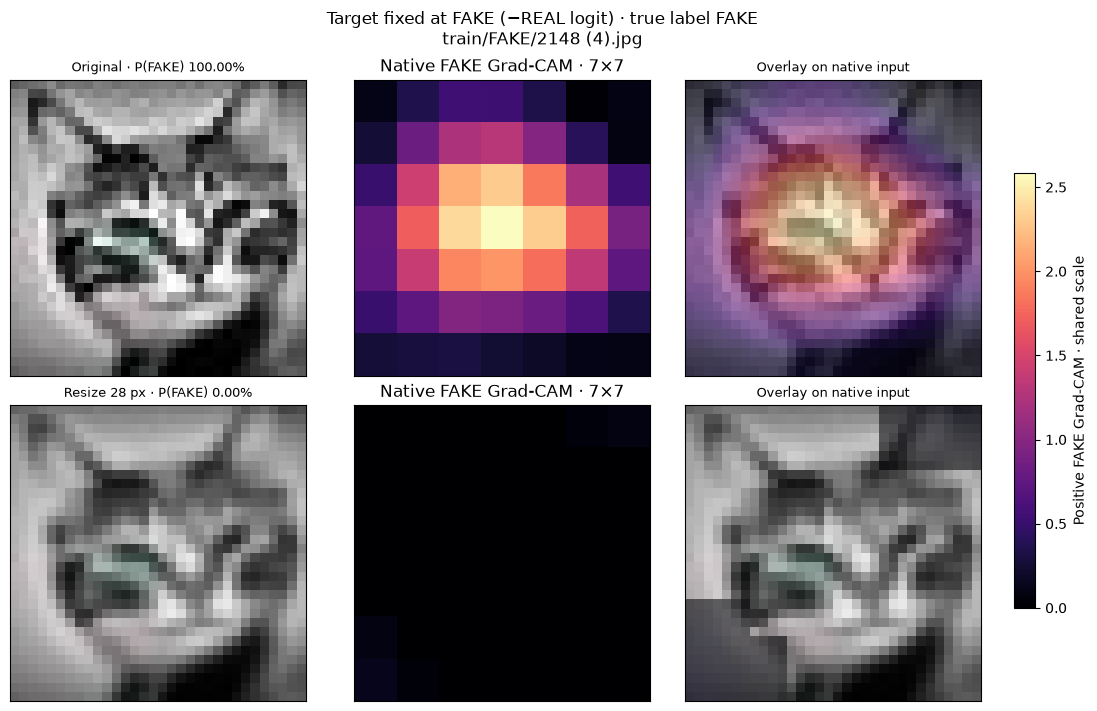

In [15]:
if default_pair is not None:
    finish_plot(gradcam_figure(default_pair), "gradcam_resize")


ResNet18 averages each of its final 512 feature maps and feeds those 512 values to one linear output. We can therefore account for its REAL logit exactly: multiply each pooled activation by its output weight, sum all 512 products, and add the bias. The heatmap below shows every contribution before and after the edit. The bars show the 12 largest changes and the sum of the remaining 500, so together they account for the entire logit change. This is the ResNet equivalent of the baseline's 64-neuron contribution chart; channel numbers do not imply semantic meanings.

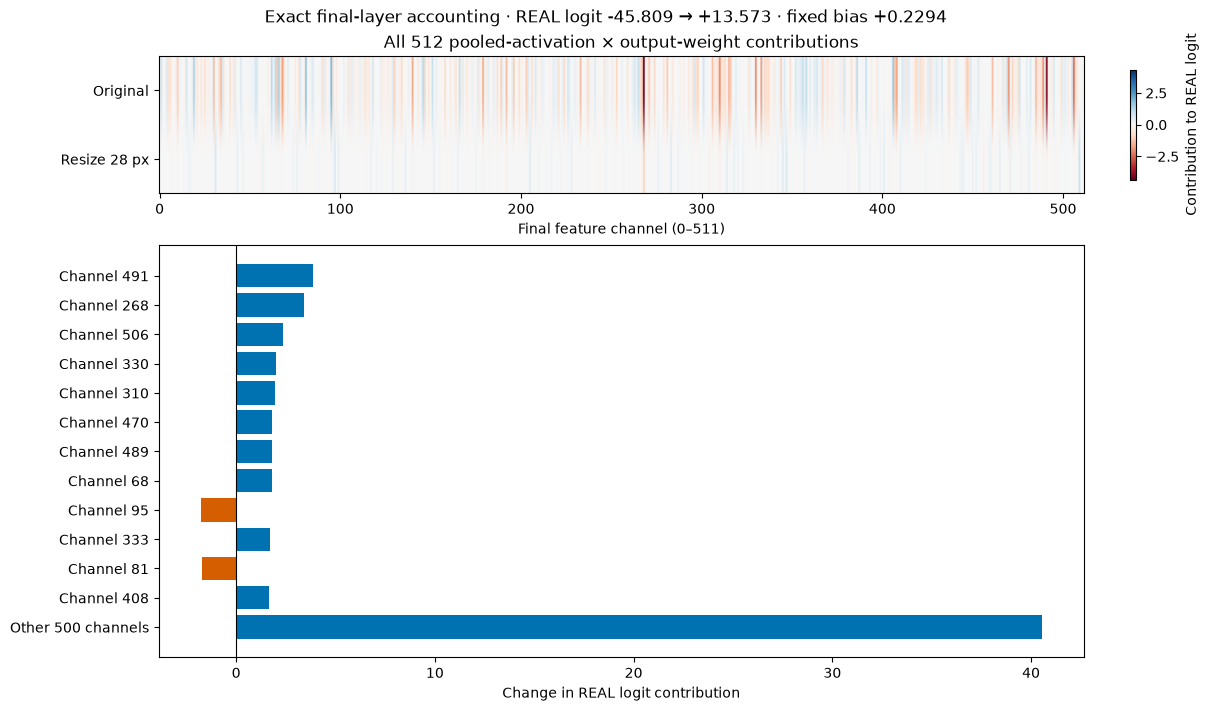

In [16]:
if default_pair is not None:
    finish_plot(contribution_figure(default_pair), "output_contributions")


We will also cover native 4×4 regions, moving in steps of two pixels, and measure the FAKE score before covering minus the score after covering. Positive red areas indicate that the covering operation reduces the FAKE score; negative blue areas indicate that it increases it. Overlapping patch effects are averaged. The reference colours are the original image's mean RGB and mid-grey, kept fixed within each before/after pair, and all four maps use one symmetric scale. The mask is applied before enlargement to 224×224. Covering creates artificial edges, so these are responses to a specified intervention rather than pixel-level causal explanations.

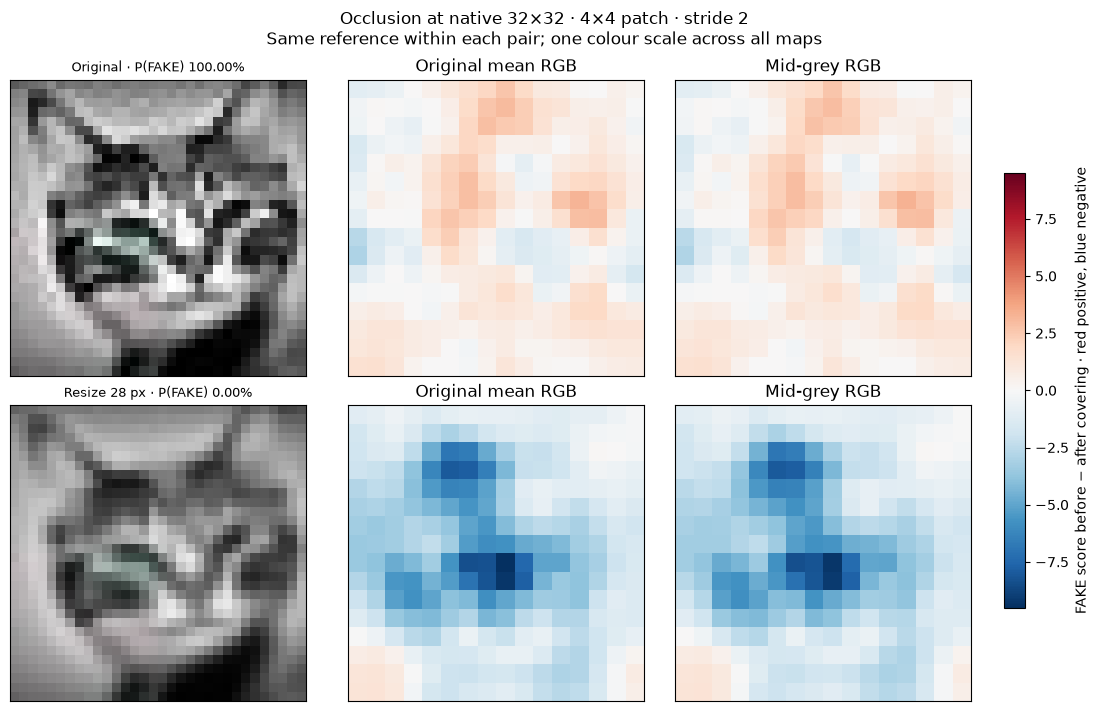

In [17]:
if default_pair is not None:
    finish_plot(occlusion_figure(default_pair), "native_occlusion")


## 5. Internal filters and channel interventions

The first grid shows the 64 learned 7×7 stem filters, with adjacent slices for red, green and blue. All use the same signed weight scale. These weights act on normalized, enlarged inputs, and BatchNorm and ReLU follow the convolution, so the weight colours are not class evidence or a complete activation calculation. The selected channel is outlined in green. For the final residual stage, the explorer instead shows each channel's weight into the REAL output; those final channels combine residual paths and are not simply RGB filters.

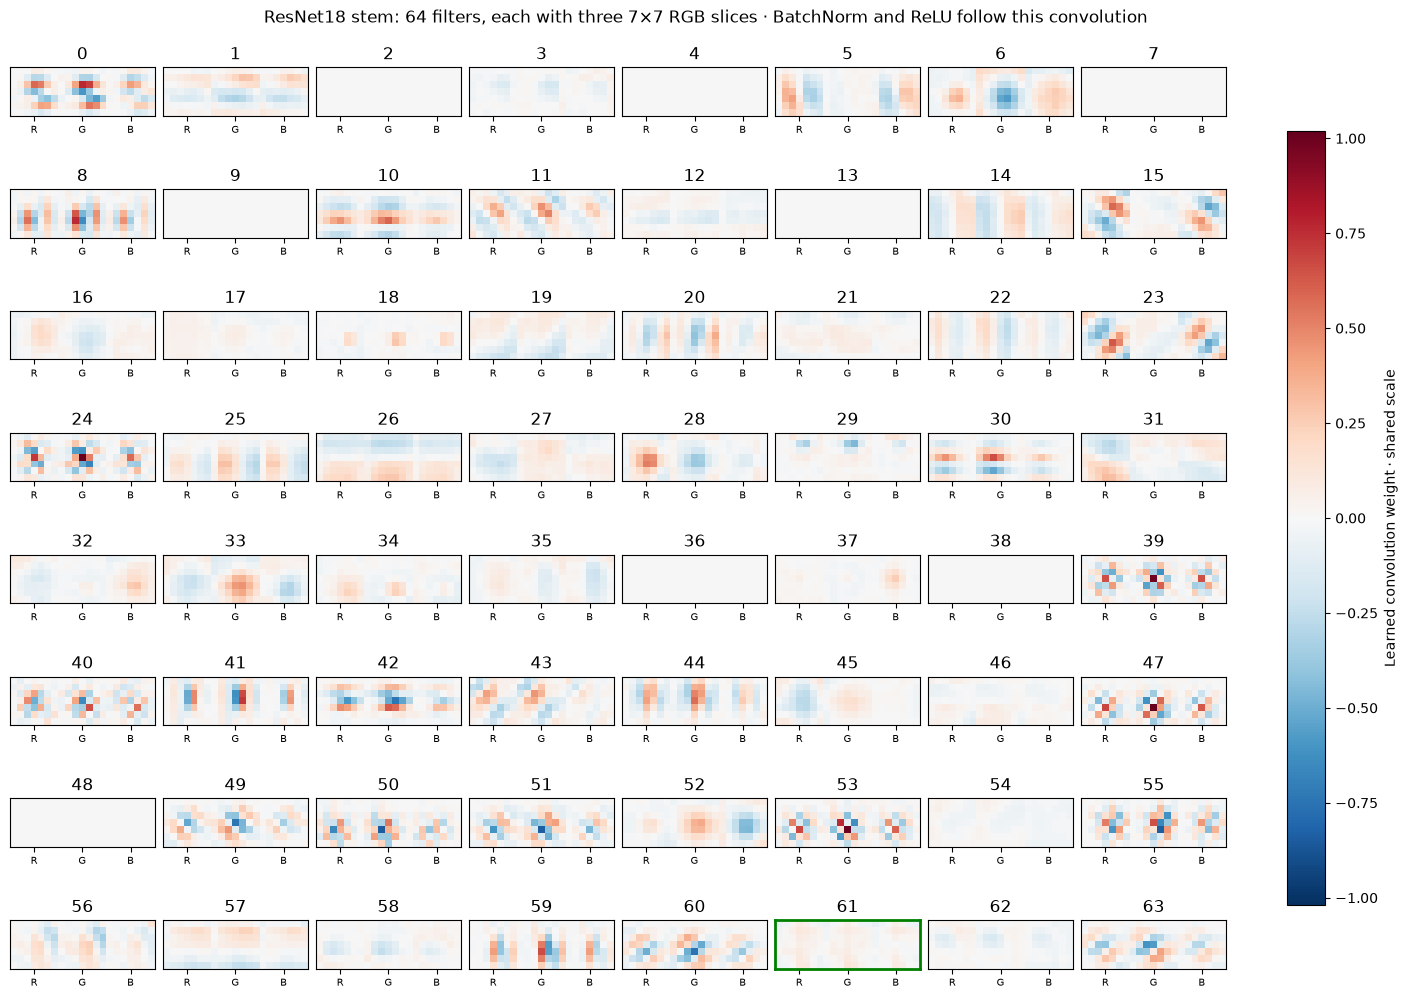

In [18]:
if default_pair is not None:
    finish_plot(weight_figure("stem", default_stem_channel), "stem_weights")


The next view follows the selected stem channel on the same original/modified pair. Its native response maps use a shared scale, and the input labels show the prediction with the full channel set to zero. The stem response is measured after Conv–BatchNorm–ReLU; the explorer also offers the final layer4 output after residual additions and ReLU. A bright activation is not automatically important for the final decision, which is why we place the intervention's prediction beside the map.

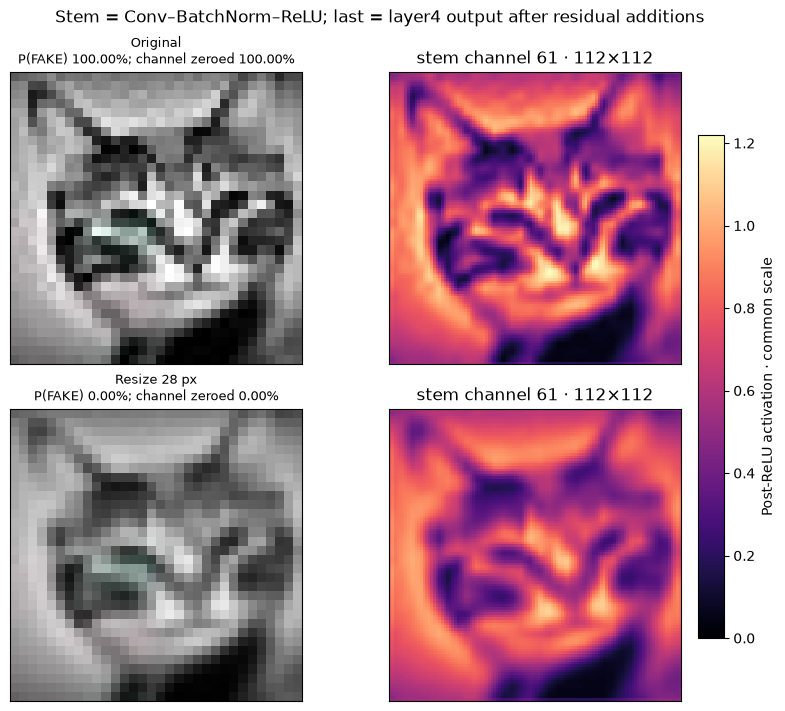

In [19]:
if default_pair is not None:
    finish_plot(
        channel_figure(default_pair, "stem", default_stem_channel), "stem_response"
    )


To investigate the pattern a channel responds to, we will show its three highest spatial activations among the same seeded, balanced 2,000-image validation sample used for the baseline's internal investigation. Selection is based on response strength, not label or correct classification. The image and response map remain separate because the final residual features have broad receptive fields; we do not draw precise object boundaries from them. Several examples can suggest a pattern to test, but do not justify assigning a semantic class label to a channel.

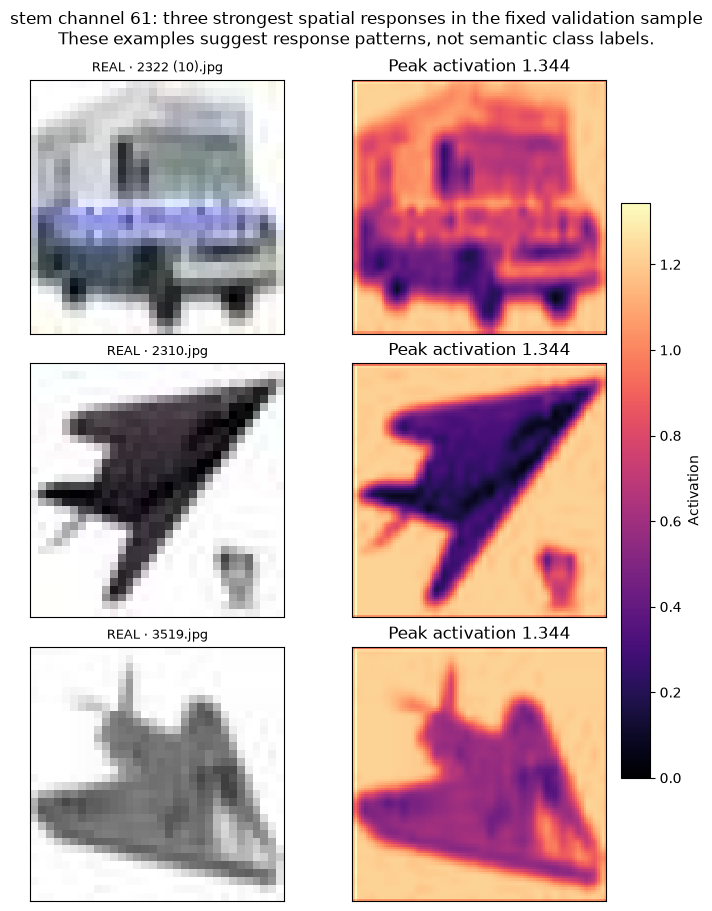

In [20]:
if default_pair is not None:
    finish_plot(examples_figure("stem", default_stem_channel), "strongest_examples")


The aggregate intervention below uses those same 2,000 validation images in original, resized and JPEG-quality-60 conditions. Every one of the 64 stem channels and 512 final channels is zeroed separately. Stem ablation runs the remaining residual network again. Final-channel ablation can be calculated exactly by subtracting that channel's pooled-activation × output-weight contribution from the logit, because only average pooling and the linear output remain.

Positive accuracy loss means removal hurts; negative values mean removal helps in that condition. For readability, the static figure shows the 20 largest absolute clean-accuracy effects in each stage, preserving their identities across conditions. The explorer exposes every channel and reports new mistakes, repaired mistakes and class-specific rates. These are descriptive, paired sample effects; channels can compensate for one another, and removal is an artificial internal state, not evidence that pruning and retraining will improve the model.

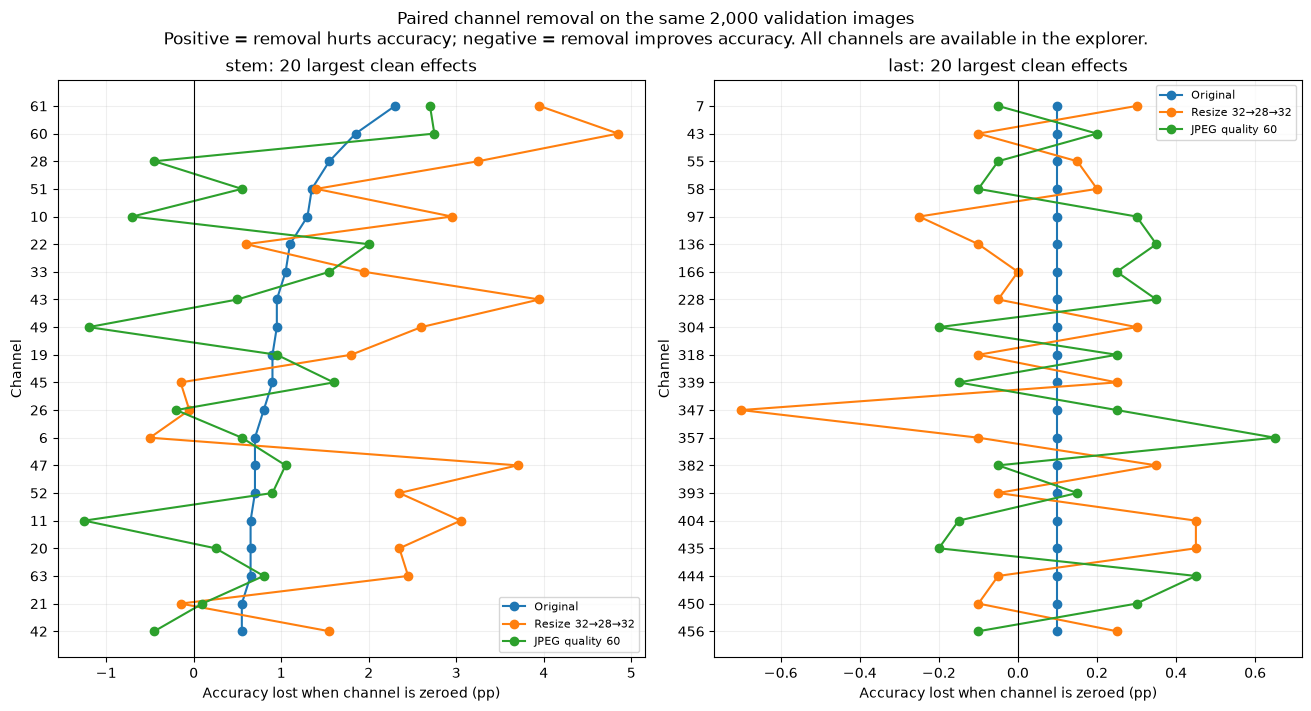

In [21]:
# Compare single-channel interventions on the fixed 2,000-image validation cohort.
if default_pair is not None:
    finish_plot(internal_figure(), "channel_ablation")


## 6. Interactive comparison

Choose a preview image, modification and strength, plus a stem or final feature channel, then press **Inspect**. The tabs connect Grad-CAM, exact output contributions, native occlusion, channel responses, weights and strongest examples. Strength zero compares an image with itself. Patch sizes 4 and 8 use strides 2 and 4. Changing controls marks the previous result as stale until the update finishes. The aggregate ablation tabs always use the fixed three conditions and the 2,000-image sample; they do not represent only the selected preview image. The controls require a live kernel, while the saved static figures can be read without one.

In [22]:
if default_pair is not None:
    resnet_explorer = draw_explorer()


## 7. What the internal views show so far

The explanation figures let us follow selected original/modified image pairs through the network. Grad-CAM shows coarse positive support for FAKE in the final feature maps. Occlusion directly measures the score change when we cover a native 4×4 patch. The contribution chart accounts for the output exactly through **512 pooled feature values multiplied by their output weights, plus the bias**. Together with stem filters, response maps and highly activating examples, these views show where a score change is accompanied by a change inside the network. They do not give a unique semantic meaning to a feature or establish which visible artifact caused every error. Upsampling the original images to 224×224 does not create additional visual information, and the final Grad-CAM grid is only 7×7 before display enlargement.

The single-channel experiments also distinguish the two models. On the shared 2,000-image validation cohort, ResNet18 scored **98.55% on originals**, **56.35% after resizing** and **96.45% after JPEG quality 60**. Removing stem channel 61 reduced these to **96.25%, 52.40% and 93.75%**, respectively. Across the tested stem channels, the largest resize improvement was only **0.65 percentage points**; across the final channels it was **0.70 points**. No tested single-channel removal repaired the large resize failure. The CNN's channel 11 had a much larger clean-versus-resize trade-off: removing it changed clean accuracy from **94.80% to 84.05%**, while resized accuracy rose from **63.80% to 80.25%**. This makes single-channel interventions less sufficient to explain the ResNet failure in this experiment; it does not prove that all of its processing is distributed or that combinations of channels would behave the same way.

These results give us a meaningful visualization project despite the **32×32 source resolution**. Phase 1 can compare score shifts, class-specific errors and sensitivity curves. Phase 2 can connect those observations to feature maps, exact output contributions and controlled internal interventions. Our conclusions should stay at that level: they concern these models, this data split and these transformations. The ResNet comparison includes ImageNet pretraining and different preprocessing as well as a deeper architecture, so the clean improvement cannot be attributed to depth alone. A useful next experiment would vary augmentation or preprocessing in a separate run, keeping the split and validation protocol fixed. The present results motivate that experiment; they do not already demonstrate that it will fix the observed sensitivity.


**Questions carried over from Phase I** (`phase1/03_resnet18_finetuning_and_visualization.ipynb`):

- **Where does the confidence shift happen?** After resizing, ResNet18 still ranks fakes above real images (ROC-AUC 0.92) but its scores move as a block toward REAL. Comparing the 512 pooled contributions for clean and resized images could show whether a few channels or a broad drift across many channels carries that shift.
- **Why is ResNet18 so sensitive to noise?** At σ = 0.10 it flags 72.6 % of real photos, against 18.3 % for the CNN. The stem filters and early feature maps on noisy real photos are the first place to look.
- **Do both models use the same fine-detail cue?** They fail on largely the same blurred fakes (Jaccard 0.68) and resized images (0.77). If the internal views point to the same image regions for those shared failures, that would support a common cue.